# Relative RV Injection Recovery w/ mock Gaia DR4- GQ Lubi B 

In this notebook we intake stellar RV, relative astrometry, and a relative planetary RV data point and combine it with mock Gaia DR4 data. In this case, relative planetary RV refers to the high resolution radial velocity taken of the companion GQ Lupi B in relation to its host's stellar RV. This is different from the planet's RV alone, which is relative to the barycenter(?)

### Imports

In [49]:
import orbitize
import numpy as np
import matplotlib.pyplot as plt
import astropy
from pathlib import Path
import pandas as pd
from astropy import units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time
from astropy.table import Table
from orbitize import gaia
import os
from orbitize import read_input, plot, priors, system, sampler, DATADIR

### Reading in Venkatesan+25 Data

In [ ]:
# import GQ Lupi b data from Venkatesan+25
input_file = os.path.join(orbitize.DATADIR, "test_val_relrv_gqlupib.csv")
data_table = read_input.read_file(input_file)
print(data_table.colnames)
data_table

['epoch', 'object', 'quant1', 'quant1_err', 'quant2', 'quant2_err', 'quant12_corr', 'quant_type', 'instrument']


epoch,object,quant1,quant1_err,quant2,quant2_err,quant12_corr,quant_type,instrument
float64,int64,float64,float64,float64,float64,float64,bytes5,str20
49445.0,1,713.8,23.3,275.5,1.1,nan,seppa,ESO 3.6 m/ComeOn+
51279.0,1,739.0,11.0,275.62,0.8,nan,seppa,HST/WFPC2
53182.0,1,732.5,3.4,275.45,0.3,nan,seppa,VLT/NACO
57128.0,1,721.0,3.0,277.6,4.0,nan,seppa,ALMA
58345.1,1,711.6,2.4,278.27,0.24,nan,seppa,SPHERE
58551.3,1,720.3,3.4,277.9,0.18,nan,seppa,NACO
58557.2,1,715.0,2.8,277.82,0.17,nan,seppa,NACO
58593.1,1,701.0,20.0,278.3,1.2,nan,seppa,MUSE
59453.975,1,-702.069,0.027,110.363,0.057,0.208,radec,Gravity


### Set up system 
If we wanted convergence, we'd run it with way more walkers and temperatures and for way more steps but we aim for speed here (speed meaning maybe 20 minutes, at least on my machine)

In [ ]:
# CREATE SYSTEM
# system parameters
num_secondary_bodies = 1
stellar_mass = 1.05 # [Msol]
plx = 6.49 # [mas]
mass_err = 0.07 # [Msol]
plx_err = 0.03 # [mas]

# MCMC parameters
num_temps = 10
num_walkers = 128
num_threads = 10
burn_steps = 2_000
num_steps = 5_000
thin = 1
tau_ref_epoch = 58_849  # MJD (2020-01-01)

'''
#if you want things to look nicer, run with more steps, walkers, and temps
n_temps=20
n_walkers=1000
n_threads=20
num_steps = 50000
total_orbits_MCMC=50000000 # n_walkers x num_steps_per_walker
burn_steps=10000
thin=10
'''

my_system = system.System(
    num_secondary_bodies,
    data_table,
    stellar_mass,
    plx,
    mass_err=mass_err,
    plx_err=plx_err,
    fit_secondary_mass=False,
    tau_ref_epoch=tau_ref_epoch,
    fitting_basis="Standard",
    
)

In [94]:
print(f"Number of parameters: {len(my_system.labels)}")
print(my_system.labels)

Number of parameters: 8
['sma1', 'ecc1', 'inc1', 'aop1', 'pan1', 'tau1', 'plx', 'mtot']


### Set up priors
We use uniform priors except for the total mass which we keep Gaussian around the previous estimate.

In [95]:
# set up priors

idx = my_system.param_idx
# Orbital priors
my_system.sys_priors[idx["ecc1"]] = priors.UniformPrior(0.0, 0.99)
my_system.sys_priors[idx["sma1"]] = priors.UniformPrior(90.0, 120.0)
my_system.sys_priors[idx["aop1"]] = priors.UniformPrior(0, 2 * np.pi)
my_system.sys_priors[idx['mtot']] = priors.GaussianPrior(1.05,0.07)

# RV only data do not constrain orientation
my_system.sys_priors[idx["inc1"]] = priors.SinPrior()
my_system.sys_priors[idx["pan1"]] = priors.UniformPrior(0, 2 * np.pi)

In [96]:
# SUMMON THE SAMPLER!
m = sampler.MCMC(
    my_system,
    num_temps=num_temps,
    num_walkers=num_walkers,
    num_threads=num_threads,
)

In [97]:
# run sampler
run = m.run_sampler(
    num_walkers * num_steps,
    burn_steps=burn_steps,
)

print(f"Posterior samples: {len(m.results.post)}")
print(f"Mean acceptance fraction: {np.mean(run.acceptance_fraction):.3f}")
myresults = m.results
myresults.save_results("relastro_GQLupib.hdf5")

Starting Burn in


/Users/ihuckabee/anaconda3/envs/exosims_env/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/ihuckabee/anaconda3/envs/exosims_env/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/ihuckabee/anaconda3/envs/exosims_env/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/ihuckabee/anaconda3/envs/exosims_env/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/ihuckabee/anaconda3/e

10000/10000 steps of burn-in complete
Burn in complete. Sampling posterior now.
50000/50000 steps completed
Run complete
Posterior samples: 6400000
Mean acceptance fraction: 0.004


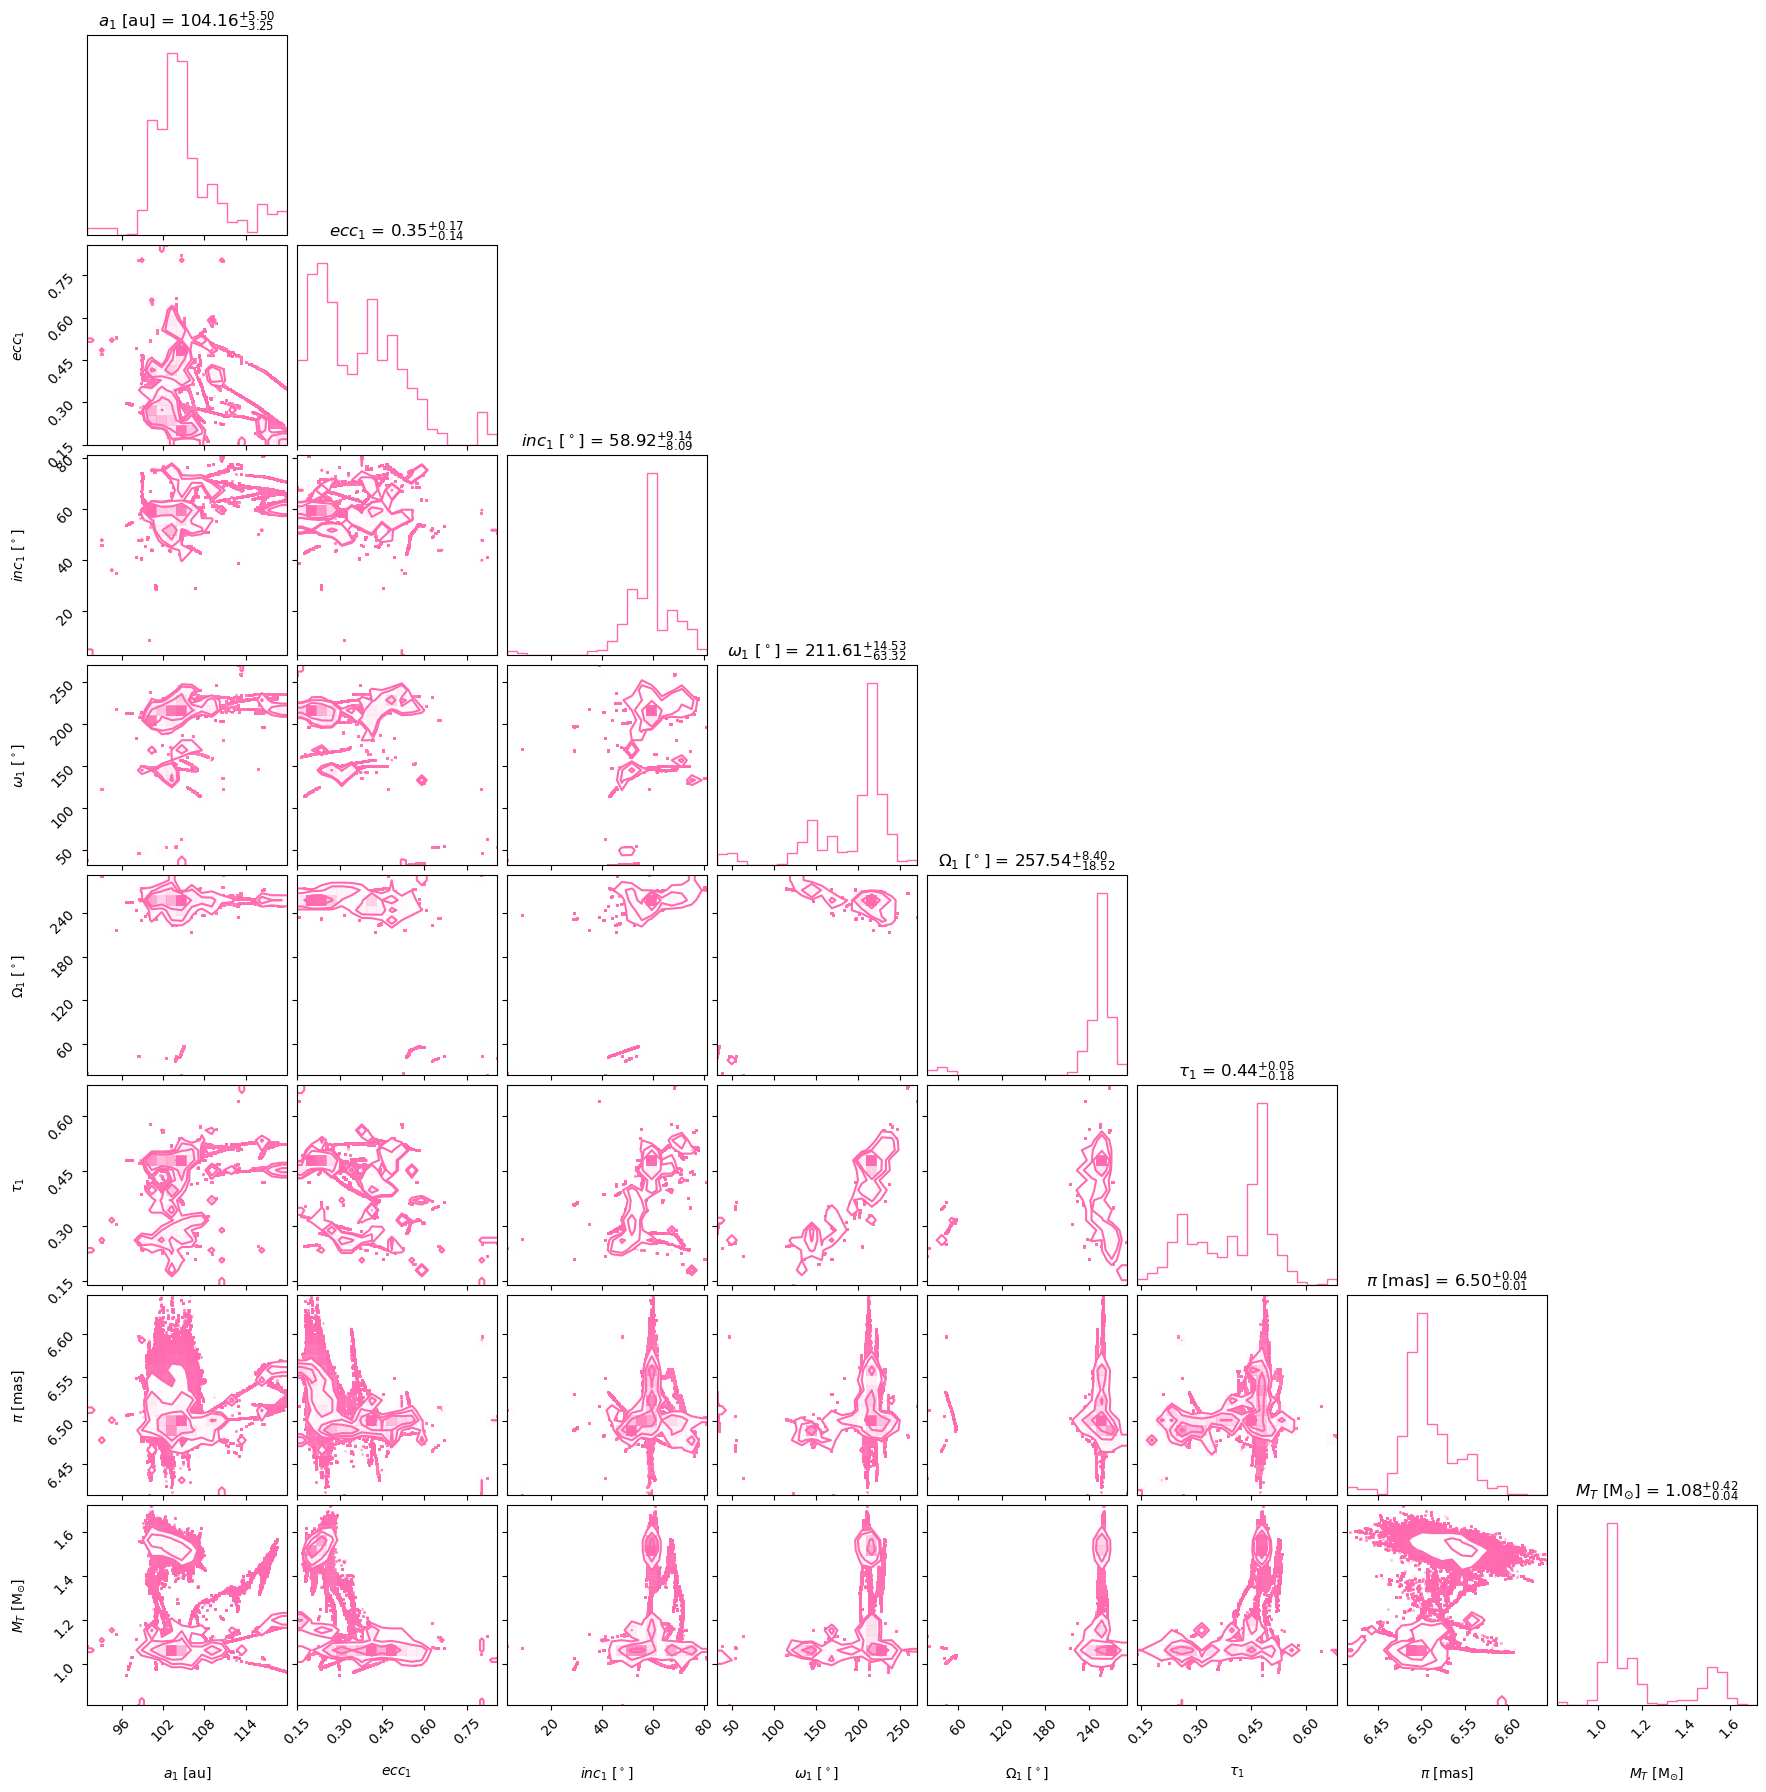

In [98]:
corner_figure = m.results.plot_corner( color="#FF69AF",show_titles=True,
)
plt.show()

### Make the previous results 'truth' for the joint fit with mock Gaia DR4 data

In [99]:
from orbitize import simulate_dr4

DR4_REF_EPOCH_MJD = simulate_dr4.DR4_REF_EPOCH_MJD
my_system = m.system
system_idx = my_system.param_idx

# Preserving the previous fit's parameter correlations
best_index = np.nanargmax(m.results.lnlike)
truth_fit = np.asarray(m.results.post)[best_index].copy()

truth_standard = my_system.basis.to_standard_basis(truth_fit.copy())
standard_idx = my_system.basis.standard_basis_idx


truth_params = {
    name: float(truth_standard[standard_idx[name]])
    for name in (
        "sma1", "ecc1", "inc1", "aop1", "pan1", "tau1",
        "plx", "mtot" 
    )
}

truth_params.update(
    alpha0=0.0,
    delta0=0.0,
    pm_ra=-14.257,
    pm_dec=-23.596,
    m0 = 0.7, 
    m1= 0.0190, 
    per1 = 1000.
)

### Simulate mock Gaia DR4 data with fake GOST file (extrapolated by like 1000 years since this is such a long period planet - only for example purposes)

In [100]:
gost_file = input_file = os.path.join(orbitize.DATADIR, "GQ_Lupi_GOST_real_plus_synthetic_1000yr_100yrcadence.csv") 
rng = np.random.default_rng(90)

dr4_mock = simulate_dr4.simulate_dr4(
    gost_file,
    truth_params,
    g_mag=11.2608,
    seed=int(rng.integers(0, 2**32)),
    tau_ref_epoch=my_system.tau_ref_epoch,

)

print(f"Simulated transits: {len(dr4_mock)}")
print(f"Companion mass: {truth_params['m1'] * u.Msun.to(u.Mjup):.3f} Mjup")
dr4_mock[:5]



Simulated transits: 79
Companion mass: 19.904 Mjup


source_id,transit_id,obs_time_tcb,parallax_factor_al,scan_pos_angle,field_of_view,centroid_pos_al,centroid_pos_error_al,ra_offset_al,quant_al,sigma_al
,,d,,rad,,mas,mas,,,
int64,int64,float64,float64,float64,str4,float64,float64,float64,float64,float64
0,0,56904.716178814415,0.704019770001665,-0.5071076020084511,FoVP,54.82241599269435,0.04484754048997559,54.82241599269435,54.82241599269435,0.04484754048997559
0,1,56904.79017882887,0.704567405741638,-0.5077308877057619,FoVF,54.76060370864373,0.04484754048997559,54.76060370864373,54.76060370864373,0.04484754048997559
0,2,56936.84076820547,0.33486498539009113,0.005049619090706762,FoVP,69.45270214428372,0.04484754048997559,69.45270214428372,69.45270214428372,0.04484754048997559
0,3,56936.91477025673,0.3378214866022196,0.0010042613814697928,FoVF,69.36358046415141,0.04484754048997559,69.36358046415141,69.36358046415141,0.04484754048997559
0,4,57029.99911091011,-0.1625641610523226,-2.9544446234906663,FoVF,-64.26866112308866,0.04484754048997559,-64.26866112308866,-64.26866112308866,0.04484754048997559


### Set up joint fit

In [101]:
# Keep the completed Venkatesan+25 fit separate
relrv_system = m.system
relrv_idx = relrv_system.param_idx

if m.results.post is None or len(m.results.post) == 0:
    raise RuntimeError("Complete the relative RV fit first.")

rv_post = np.asarray(m.results.post)

# Mock OHP timestamps are JD(TCB); the reader converts them to MJD.
# Already an Astropy Table in MJD(TCB).
mock_table = dr4_mock.copy()

mock_gaia = gaia.DR4LogProb(
    0,
    mock_table,
    ref_epoch_mjd=DR4_REF_EPOCH_MJD,
    jitter_prior=priors.LogUniformPrior(1e-4, 1.0),
)

# Include the original RV measurements and the mock Gaia measurements.
joint_system = system.System(
    relrv_system.num_secondary_bodies,
    relrv_system.data_table.copy(),
    relrv_system.stellar_or_system_mass,
    relrv_system.plx,
    mass_err=relrv_system.mass_err,
    plx_err=relrv_system.plx_err,
    fit_secondary_mass=True,
    gaia=mock_gaia,
    tau_ref_epoch=relrv_system.tau_ref_epoch,
    fitting_basis="Standard",
)
joint_idx = joint_system.param_idx
for name, column in relrv_idx.items():
    if name in joint_idx:
        joint_system.sys_priors[joint_idx[name]] = (
            relrv_system.sys_priors[column]
        )

joint_mcmc = sampler.MCMC(
    joint_system,
    num_temps=num_temps,
    num_walkers=num_walkers,
    num_threads=num_threads,
)
sampled_idx = joint_mcmc.sampled_param_idx
positions = joint_mcmc.curr_pos.reshape(-1, joint_mcmc.num_params)

# RV posterior starting positions. inclination/LAN keep their prior draws.
warm_names = [
    name for name in sampled_idx
    if name in relrv_idx and name not in ("inc1", "pan1")
]
rv_columns = [relrv_idx[name] for name in warm_names]
joint_columns = [sampled_idx[name] for name in warm_names]

draws = rng.choice(len(rv_post), size=len(positions), replace=True)
positions[:, joint_columns] = rv_post[draws][:, rv_columns]

# Compute each trial stellar reflex orbit.
full_positions = joint_mcmc._fill_in_fixed_params(positions)
standard_positions = joint_system.basis.to_standard_basis(
    full_positions.T.copy()
)
ra, dec, _, _ = joint_system.compute_all_orbits(
    standard_positions, epochs=mock_gaia.epochs_mjd,
)
orbit_al = -(
    ra[:, 0, :] * mock_gaia.sin_scan[:, None]
    + dec[:, 0, :] * mock_gaia.cos_scan[:, None]
)

# Solve position/proper motion only to initialize the walkers.
# These parameters remain freely sampled during MCMC.
linear_columns = [
    sampled_idx[name]
    for name in ("alpha0", "delta0", "pm_ra", "pm_dec")
]

for walker, params in enumerate(full_positions):
    sigma = np.hypot(
        mock_gaia.centroid_pos_error_al,
        params[joint_idx["dr4_jitter"]],
    )
    target = (
        mock_gaia.centroid_pos_al
        - params[joint_idx["plx"]] * mock_gaia.parallax_factor_al
        - orbit_al[:, walker]
    )

    positions[walker, linear_columns] = gaia.HGCALogProb._linear_pm_fit(
        epochs=mock_gaia.dt_yr,
        raoff_planet=target * mock_gaia.sin_scan,
        decoff_planet=target * mock_gaia.cos_scan,
        epoch_ref_ra=0.0,
        epoch_ref_dec=0.0,
        sin_phi=mock_gaia.cos_scan,
        cos_phi=mock_gaia.sin_scan,
        errs=sigma,
    )

joint_mcmc.check_prior_support()

print(
    f"Joint data: {len(joint_system.data_table)} RVs and astrometry msmts "
    f"+ {mock_gaia.n_obs} Gaia transits"
)


Joint data: 14 RVs and astrometry msmts + 79 Gaia transits


### Run joint fit

In [102]:
# run sampler
joint_run = joint_mcmc.run_sampler(
    joint_mcmc.num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
joint_post = joint_mcmc.results.post

print(f"Joint posterior samples: {len(joint_post)}")
print(
    f"Cold chain acceptance: "
    f"{np.mean(joint_run.acceptance_fraction[0]):.3f}"
)

Starting Burn in


/Users/ihuckabee/anaconda3/envs/exosims_env/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/ihuckabee/anaconda3/envs/exosims_env/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/ihuckabee/anaconda3/envs/exosims_env/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/ihuckabee/anaconda3/envs/exosims_env/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/ihuckabee/anaconda3/e

10000/10000 steps of burn-in complete
Burn in complete. Sampling posterior now.
50000/50000 steps completed
Run complete
Joint posterior samples: 640000
Cold chain acceptance: 0.029


### Plot that badboi

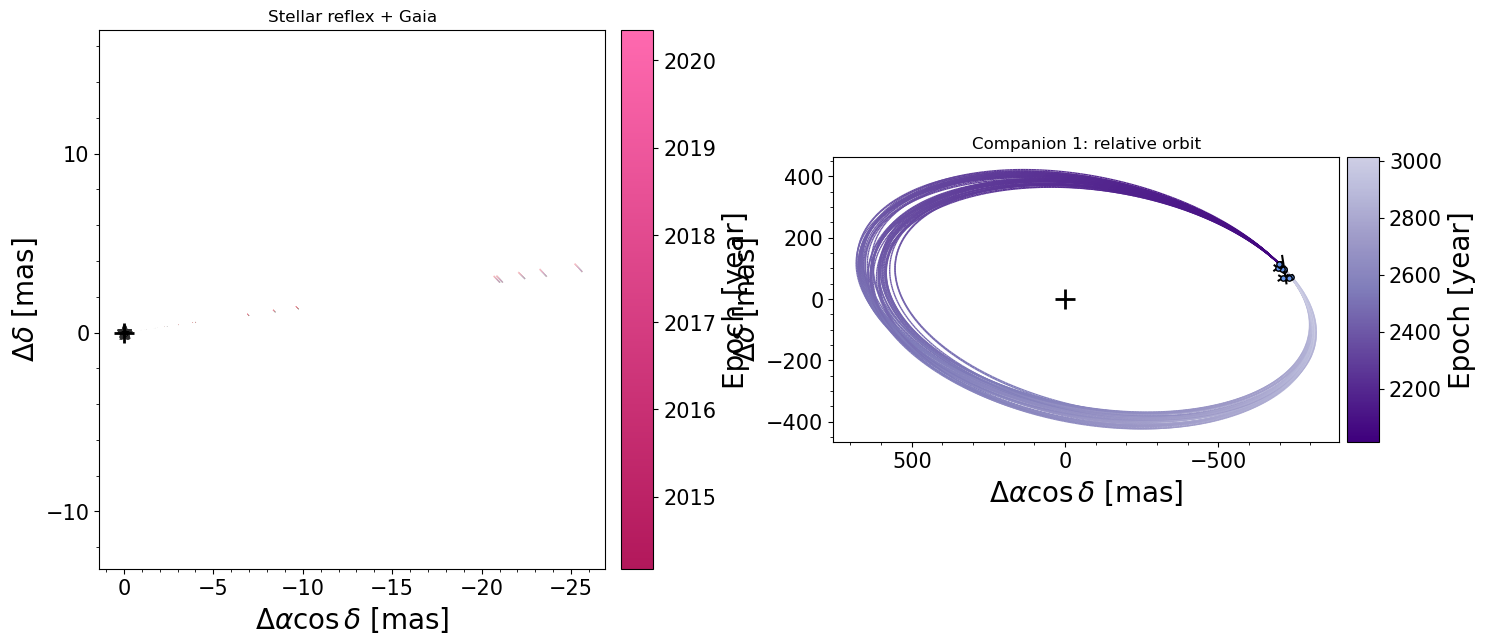

In [112]:
import importlib
import orbitize.plot as orbitize_plot

importlib.reload(orbitize_plot)

fig = joint_mcmc.results.plot_dr4_orbit(
    joint_mcmc.system,
    include_planet=True,
    planet_to_plot=1,
    num_orbits_to_plot=50,
    include_jitter=True,
)

### Plot w/ and w/o mock DR4 data

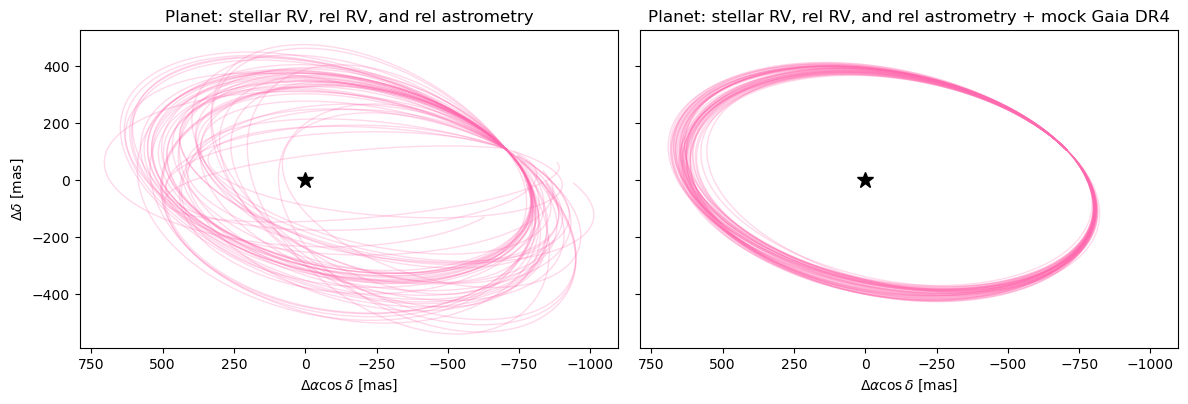

In [104]:
# PLOT PLANET ORBIT
rv_orbit_post = np.asarray(m.results.post)
joint_orbit_post = np.asarray(joint_mcmc.results.post)

rv_orbit_draws = rv_orbit_post[
    rng.choice(     
        len(rv_orbit_post), size=min(50, len(rv_orbit_post)),
        replace=False,
    )
]
joint_orbit_draws = joint_orbit_post[
    rng.choice(
        len(joint_orbit_post), size=min(50, len(joint_orbit_post)),
        replace=False,
    )
]
with plt.style.context("default"):
    planet_fig, planet_axes = plt.subplots(
        1, 2, figsize=(12, 5), sharex=True, sharey=True,
    )

    for ax, orbit_system, orbit_draws, title in zip(
        planet_axes,
        [m.system, joint_mcmc.system],
        [rv_orbit_draws, joint_orbit_draws],
        ["Planet: stellar RV, rel RV, and rel astrometry", "Planet: stellar RV, rel RV, and rel astrometry + mock Gaia DR4"],
    ):
        for draw in orbit_draws:
            standard = orbit_system.basis.to_standard_basis(draw.copy())
            period_days = 365.25 * 1000# draw[orbit_system.param_idx["per1"]]
            epochs = np.linspace(
                orbit_system.tau_ref_epoch,
                orbit_system.tau_ref_epoch + period_days,
                500,
            )
            ra, dec, _, _ = orbit_system.compute_all_orbits(
                standard, epochs=epochs,
            )

            # Body 1: planet–star separation, without reflex scaling.
            ax.plot(
                ra[:, 1, 0], dec[:, 1, 0],
                color="#FF69AF", alpha=0.25, lw=1,
            )

        ax.plot(0, 0, "*", color="black", ms=12)
        ax.set(
            title=title,
            xlabel=r"$\Delta\alpha\cos\delta$ [mas]",
        )
        ax.set_aspect("equal", adjustable="box")

    planet_axes[0].set_ylabel(r"$\Delta\delta$ [mas]")
    planet_axes[0].invert_xaxis()
    planet_fig.tight_layout()
    plt.show()

### Final Corner Plot

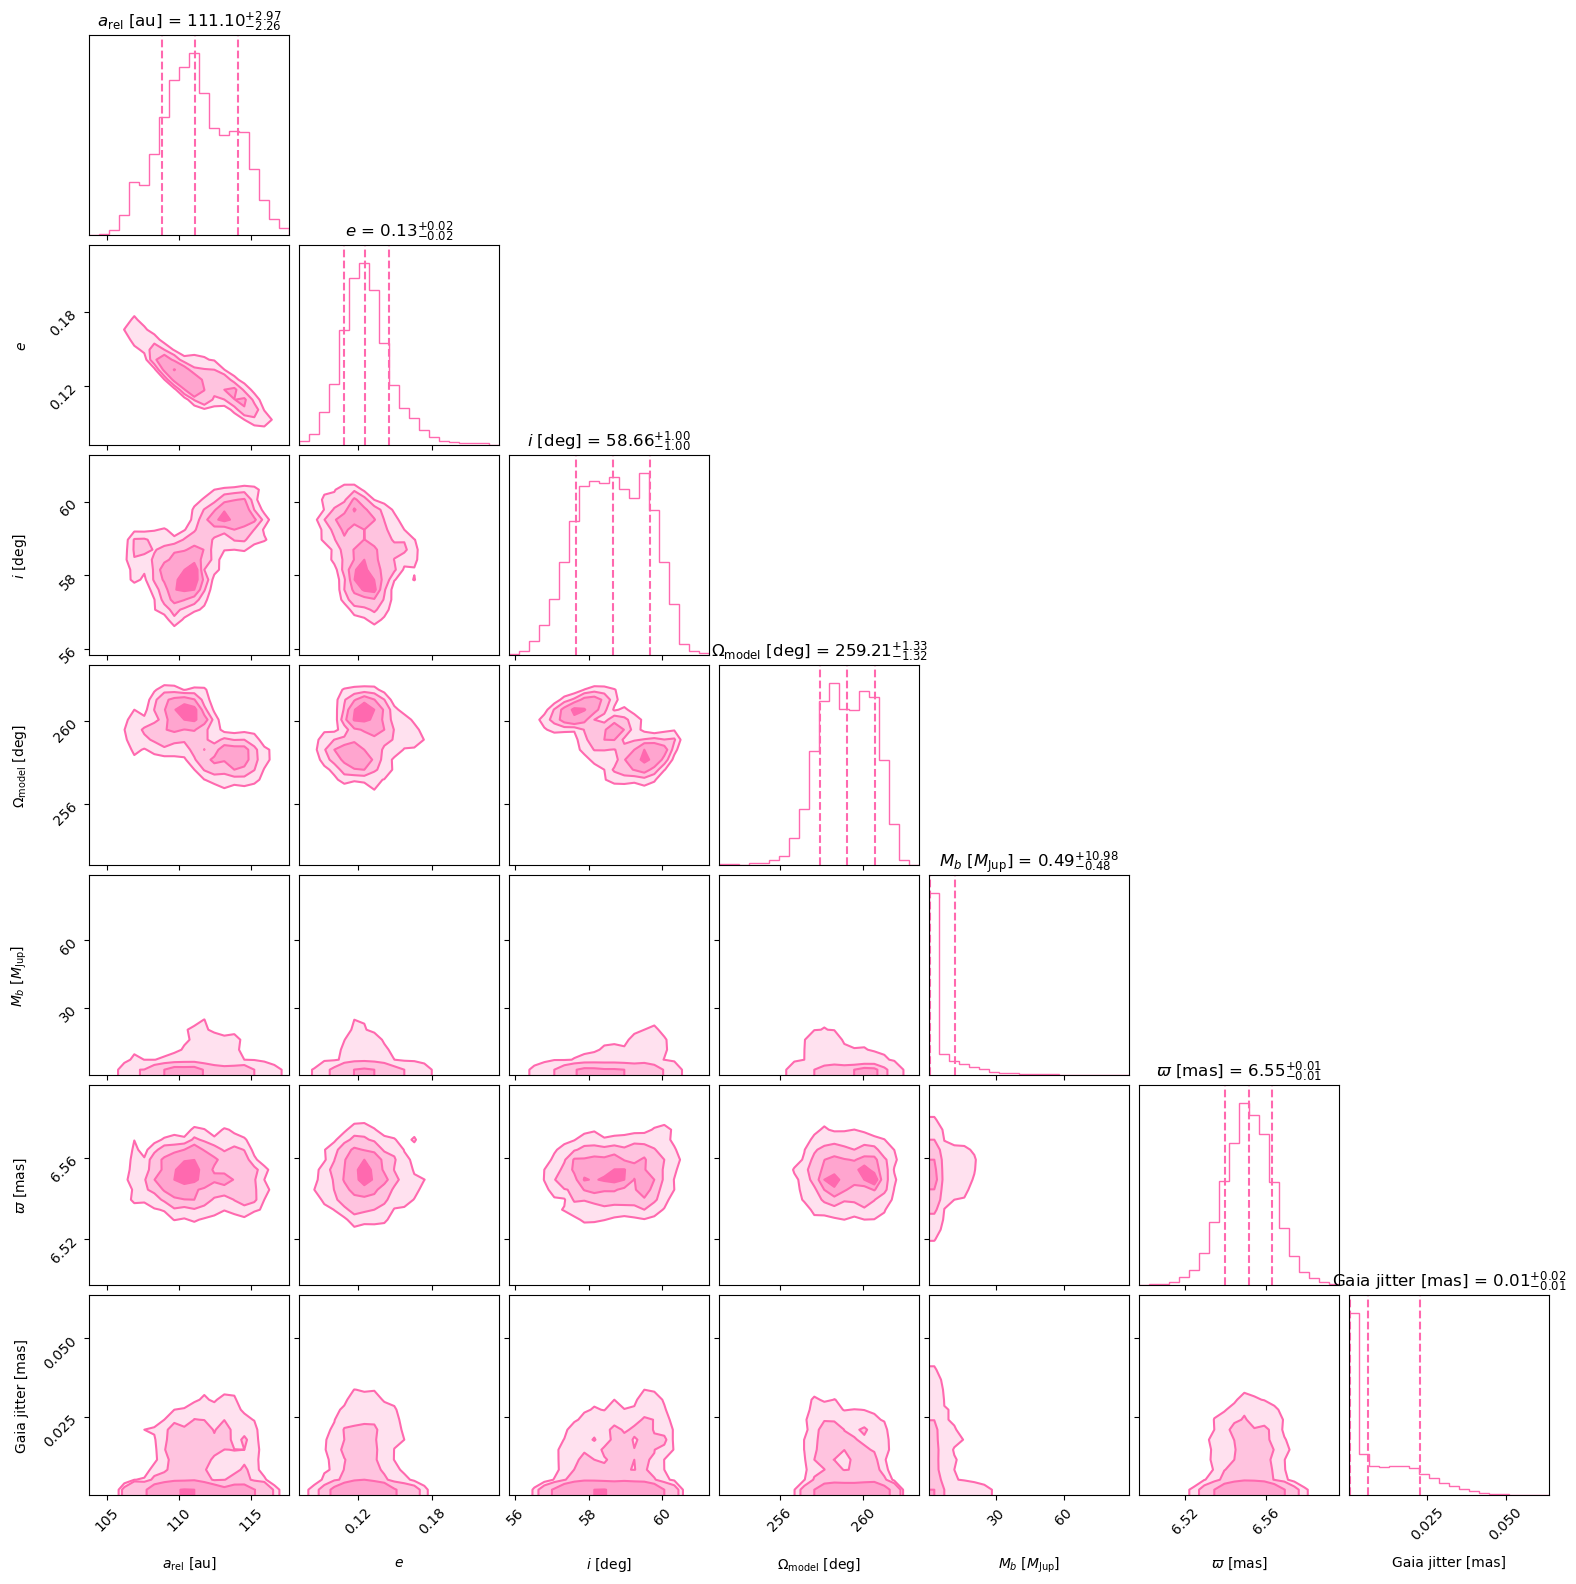

In [105]:
# final corner plot
from copy import copy

joint_results = joint_mcmc.results
plot_results = copy(joint_results)  #

draws = rng.choice(
    len(joint_results.post),
    size=min(20_000, len(joint_results.post)),
    replace=False,
)
basis = joint_mcmc.system.basis
plot_results.post = basis.to_standard_basis(
    joint_results.post[draws].T.copy()
).T
plot_results.lnlike = joint_results.lnlike[draws]
plot_results.param_idx = basis.standard_basis_idx.copy()

with plt.style.context("default"):
    corner_figure = plot_results.plot_corner(
        param_list=["sma1", "ecc1", "inc1", "pan1", "m1", "plx", "dr4_jitter"],
        labels=[
            r"$a_{\rm rel}$ [au]", r"$e$", r"$i$ [deg]",
            r"$\Omega_{\rm model}$ [deg]", r"$M_b$ [$M_{\rm Jup}$]",
            r"$\varpi$ [mas]", "Gaia jitter [mas]",
        ],
        color="#FF69AF",
        quantiles=[0.16, 0.5, 0.84],
        show_titles=True,
        plot_datapoints=False,
        fill_contours=True,
        max_n_ticks=3,
    )
    plt.show()